# Week 5 — Support Vector Machines, the Kernel Trick, and Regularization *(In-depth analysis II)*

**Project:** Predicting Loan Repayment Risk Using LendingClub Data
**Target:** charge-off (1) vs fully paid (0), with the same features and the same train/test split as Week 4.

Questions:
1. Does a more flexible, nonlinear decision boundary (RBF kernel) separate charge-offs better than the linear logistic baseline?
2. How do the regularization parameter **C** and the RBF width **γ** trade off fit against generalization?
3. Is any gain worth the loss of interpretability and the extra computation?

**Key ideas**
* An SVM finds the boundary with the **largest margin** between classes. Points inside the margin or misclassified are penalized, and **C** sets that penalty: large C fits the training data closely (less regularization), small C gives a wider, smoother margin (more regularization).
* **Kernel trick:** the SVM only needs inner products between observations. Replacing ⟨x, x′⟩ with a kernel K(x, x′) fits a linear boundary in a much richer (for the RBF kernel, infinite-dimensional) feature space without ever building that space. RBF: K(x, x′) = exp(−γ‖x − x′‖²). **γ** sets how far one training point's influence reaches; a large γ gives a wiggly boundary and a higher overfitting risk.
* SVMs use distances, so **scaling is required**. It is done inside the pipeline.

**Computation:** kernel SVC training time grows at least quadratically with the number of rows (scikit-learn documentation), so the RBF model is **tuned on a 10,000-row subsample and refit on 20,000 rows** of the training set. `LinearSVC` scales to the full training set. **All models are evaluated on the identical full test set** from Week 1.

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, validation_curve, train_test_split
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix, precision_recall_curve,
                             RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)  # spurious numpy 2.x + macOS Accelerate warning; results unaffected
import os
os.environ["PYTHONWARNINGS"] = ",".join(f"ignore:{m} encountered in matmul:RuntimeWarning"
                                        for m in ("divide by zero", "overflow", "invalid value"))  # same filter for parallel workers
warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
SVM_TUNE_N = 10_000   # rows used for the RBF grid search
SVM_FIT_N = 20_000    # rows used to refit the chosen RBF SVM
LIN_TUNE_N = 30_000   # rows used for the LinearSVC C curve

NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "grade", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]

df = pd.read_parquet(DATA)
df[NUM] = df[NUM].astype(float)
for c in CAT:
    df[c] = df[c].astype("string").fillna("Missing").astype(object)
CAT = [c for c in CAT if df.loc[df.split == "train", c].nunique() > 1]
train, test = df[df.split == "train"], df[df.split == "test"]
X_tr, y_tr = train[NUM + CAT], train["target"].astype(int)
X_te, y_te = test[NUM + CAT], test["target"].astype(int)
print(f"train {X_tr.shape} | test {X_te.shape} | test charge-off rate {y_te.mean():.2%}")

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), CAT),
    ])

def strat_subsample(X, y, n, seed=RANDOM_STATE):
    if n >= len(X):
        return X, y
    Xs, _, ys, _ = train_test_split(X, y, train_size=n, stratify=y, random_state=seed)
    return Xs, ys

def metrics(y, score, thr):
    pred = (score >= thr).astype(int)
    return {"ROC_AUC": roc_auc_score(y, score), "PR_AUC(AP)": average_precision_score(y, score),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred)}

def f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f[:-1])])

CV3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
CV5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

scikit-learn 1.6.1


train (140000, 24) | test (60000, 24) | test charge-off rate 14.87%


## 1. The kernel trick, visualized

To make the idea visible, the SVMs here use only **two standardized features** (FICO and DTI) on a balanced 3,000-loan sample. A linear kernel can only draw a straight line. Polynomial and RBF kernels bend the boundary, and a very large γ produces an overfit, island-like boundary.

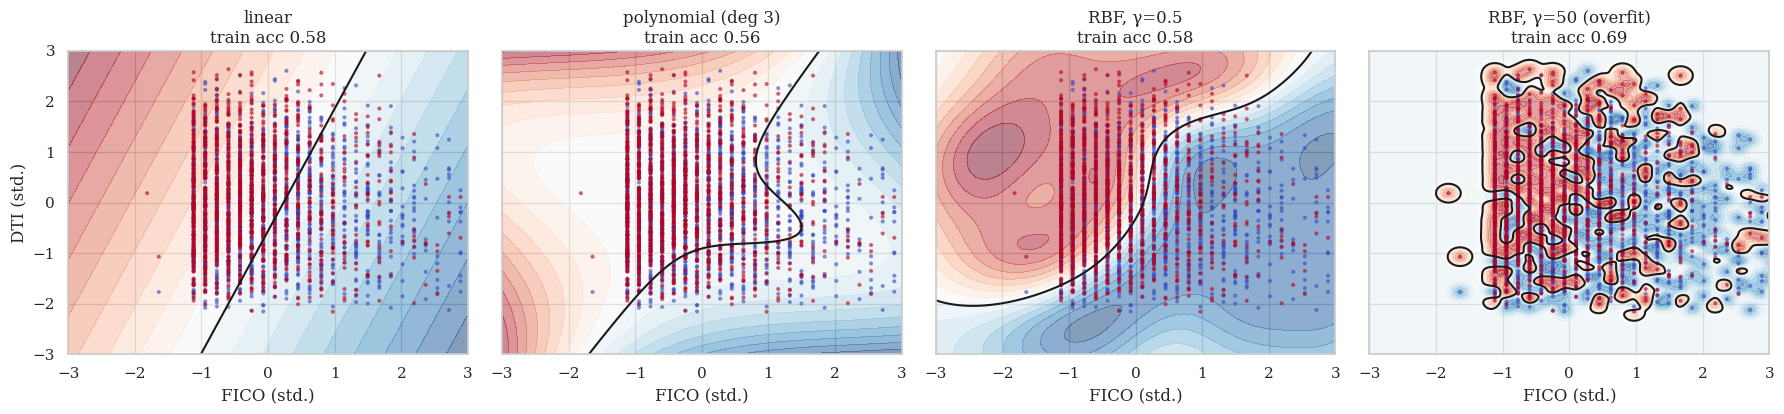

In [2]:
viz = pd.concat([g.sample(min(1500, len(g)), random_state=RANDOM_STATE) for _, g in train.groupby("target")])
V = StandardScaler().fit_transform(viz[["fico", "dti"]].fillna(viz[["fico", "dti"]].median()))
yv = viz["target"].values
xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
kernels = [("linear", SVC(kernel="linear", C=1)), ("polynomial (deg 3)", SVC(kernel="poly", degree=3, C=1)),
           ("RBF, γ=0.5", SVC(kernel="rbf", gamma=0.5, C=1)), ("RBF, γ=50 (overfit)", SVC(kernel="rbf", gamma=50, C=1))]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3), sharey=True)
for ax, (name, m) in zip(axes, kernels):
    m.fit(V, yv)
    Z = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=20, cmap="RdBu_r", alpha=0.5)
    ax.contour(xx, yy, Z, levels=[0], colors="k", linewidths=1.5)
    ax.scatter(V[:, 0], V[:, 1], c=yv, cmap="coolwarm", s=4, alpha=0.5)
    ax.set(title=f"{name}\ntrain acc {m.score(V, yv):.2f}", xlabel="FICO (std.)", xlim=(-3, 3), ylim=(-3, 3))
axes[0].set_ylabel("DTI (std.)")
plt.tight_layout(); plt.savefig(FIG_DIR / "week5_kernel_trick.png", dpi=200); plt.show()

## 2. Regularization: the effect of C (linear SVM)

Validation curve for `LinearSVC` on a 30,000-row training subsample. Small C means a strong penalty on ‖w‖ (wide margin, simple model); large C means a weak penalty. If the train and CV curves pull apart at large C, the model is overfitting.

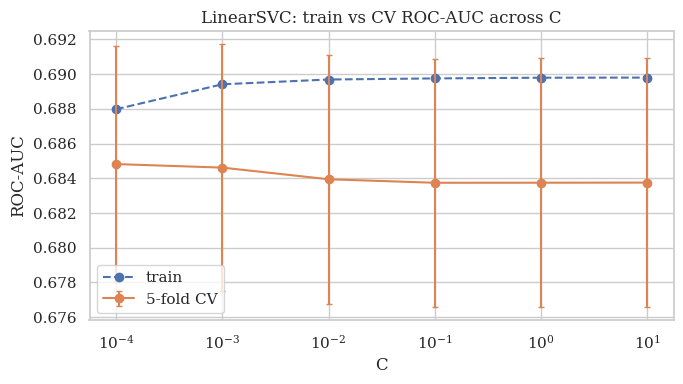

Best C for LinearSVC: 0.0001


In [3]:
X_lin, y_lin = strat_subsample(X_tr, y_tr, LIN_TUNE_N)
C_grid = np.logspace(-4, 1, 6)
lin_pipe = Pipeline([("pre", make_pre()), ("svm", LinearSVC(dual=False, max_iter=5000))])
tr_sc, cv_sc = validation_curve(lin_pipe, X_lin, y_lin, param_name="svm__C", param_range=C_grid,
                                cv=CV5, scoring="roc_auc", n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(C_grid, tr_sc.mean(1), marker="o", ls="--", label="train")
ax.errorbar(C_grid, cv_sc.mean(1), yerr=cv_sc.std(1), marker="o", capsize=2, label="5-fold CV")
ax.set(xscale="log", xlabel="C", ylabel="ROC-AUC", title="LinearSVC: train vs CV ROC-AUC across C"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "week5_linear_C_curve.png", dpi=200); plt.show()
best_C_lin = float(C_grid[cv_sc.mean(1).argmax()])
print("Best C for LinearSVC:", best_C_lin)

In [4]:
# LinearSVC refit on the FULL training set (it scales linearly with rows)
lin_svm = Pipeline([("pre", make_pre()), ("svm", LinearSVC(C=best_C_lin, dual=False, max_iter=5000))])
t0 = time.time(); lin_svm.fit(X_tr, y_tr); lin_secs = time.time() - t0
s_lin_te, s_lin_tr = lin_svm.decision_function(X_te), lin_svm.decision_function(X_tr)
print(f"LinearSVC full-train fit {lin_secs:.1f}s | train AUC {roc_auc_score(y_tr, s_lin_tr):.4f} | test AUC {roc_auc_score(y_te, s_lin_te):.4f}")

LinearSVC full-train fit 0.9s | train AUC 0.6836 | test AUC 0.6803


## 3. RBF-kernel SVM: joint tuning of C, γ, and class weight

Grid: C ∈ {0.1, 1, 10} × γ ∈ {'scale', 0.01, 0.1} × class_weight ∈ {None, 'balanced'}, 3-fold stratified CV on a 10,000-row training subsample, scored on ROC-AUC. `gamma='scale'` (the scikit-learn default) is 1 / (n_features × Var(X)). SVC does not produce probabilities by default, so ROC-AUC uses the **decision function** (signed distance from the boundary). That is enough for ranking metrics.

In [5]:
X_tune, y_tune = strat_subsample(X_tr, y_tr, SVM_TUNE_N)
grid = {"svm__C": [0.1, 1, 10], "svm__gamma": ["scale", 0.01, 0.1], "svm__class_weight": [None, "balanced"]}
rbf_search = GridSearchCV(Pipeline([("pre", make_pre()), ("svm", SVC(kernel="rbf", cache_size=1000))]), grid,
                          scoring="roc_auc", cv=CV3, return_train_score=True, n_jobs=-1)
t0 = time.time(); rbf_search.fit(X_tune, y_tune); print(f"RBF grid search: {time.time()-t0:.0f}s")
print("Best:", rbf_search.best_params_, f"CV ROC-AUC {rbf_search.best_score_:.4f}")
res = pd.DataFrame(rbf_search.cv_results_)
res = res.assign(C=res["param_svm__C"], gamma=res["param_svm__gamma"].map(str), class_weight=res["param_svm__class_weight"].map(str))
res["train_minus_cv"] = res["mean_train_score"] - res["mean_test_score"]
res[["C", "gamma", "class_weight", "mean_train_score", "mean_test_score", "train_minus_cv", "mean_fit_time"]].sort_values("mean_test_score", ascending=False)

RBF grid search: 63s
Best: {'svm__C': 0.1, 'svm__class_weight': 'balanced', 'svm__gamma': 0.01} CV ROC-AUC 0.6875


,C,gamma,class_weight,mean_train_score,mean_test_score,train_minus_cv,mean_fit_time
4,0.1000,0.01,balanced,0.7035,0.6875,0.0161,4.7969
3,0.1000,scale,balanced,0.7271,0.6832,0.0440,4.7034
10,1.0000,0.01,balanced,0.7349,0.6763,0.0586,4.0143
5,0.1000,0.1,balanced,0.7869,0.6743,0.1126,4.6514
9,1.0000,scale,balanced,0.8321,0.6638,0.1683,3.8741
16,10.0000,0.01,balanced,0.8137,0.6559,0.1578,4.1465
11,1.0000,0.1,balanced,0.9835,0.6302,0.3534,3.7189
8,1.0000,0.1,None,0.9918,0.6080,0.3838,3.0380
2,0.1000,0.1,None,0.9918,0.6080,0.3838,2.9229
15,10.0000,scale,balanced,0.9669,0.6073,0.3596,3.8869


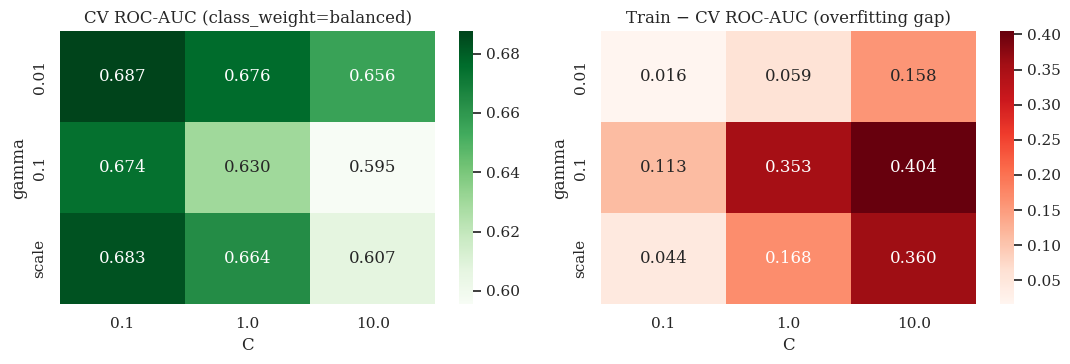

In [6]:
# Heatmaps: CV ROC-AUC and train−CV gap (overfitting) across C × γ for the best class_weight
best_cw = str(rbf_search.best_params_["svm__class_weight"])
sub = res[res["class_weight"] == best_cw]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.heatmap(sub.pivot(index="gamma", columns="C", values="mean_test_score"), annot=True, fmt=".3f", cmap="Greens", ax=axes[0])
axes[0].set_title(f"CV ROC-AUC (class_weight={best_cw})")
sns.heatmap(sub.pivot(index="gamma", columns="C", values="train_minus_cv"), annot=True, fmt=".3f", cmap="Reds", ax=axes[1])
axes[1].set_title("Train − CV ROC-AUC (overfitting gap)")
plt.tight_layout(); plt.savefig(FIG_DIR / "week5_rbf_grid.png", dpi=200); plt.show()

## 4. Refit the chosen RBF SVM and evaluate on the shared test set

The threshold on the decision function is chosen to maximize F1 on **out-of-fold** predictions within the fit sample, as in Week 4.

In [7]:
X_fit, y_fit = strat_subsample(X_tr, y_tr, SVM_FIT_N, seed=RANDOM_STATE + 1)
best_params = {k.replace("svm__", ""): v for k, v in rbf_search.best_params_.items()}
rbf_svm = Pipeline([("pre", make_pre()), ("svm", SVC(kernel="rbf", cache_size=1000, **best_params))])
t0 = time.time(); rbf_svm.fit(X_fit, y_fit); rbf_secs = time.time() - t0
t0 = time.time(); s_rbf_te = rbf_svm.decision_function(X_te); pred_secs = time.time() - t0
s_rbf_fit = rbf_svm.decision_function(X_fit)
print(f"RBF SVC: fit {rbf_secs:.0f}s on {len(X_fit):,} rows, {rbf_svm['svm'].n_support_.sum():,} support vectors; "
      f"scoring {len(X_te):,} test rows took {pred_secs:.0f}s")

oof_rbf = cross_val_predict(rbf_svm, X_fit, y_fit, cv=CV3, method="decision_function", n_jobs=-1)
THR_RBF = f1_threshold(y_fit, oof_rbf)
oof_lin = cross_val_predict(lin_svm, X_tr, y_tr, cv=CV3, method="decision_function", n_jobs=-1)
THR_LIN = f1_threshold(y_tr, oof_lin)

# Fair-comparison reference: logistic regression trained on the SAME 20k rows as the RBF SVM
lr_small = Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=5000))]).fit(X_fit, y_fit)
s_lr_small = lr_small.predict_proba(X_te)[:, 1]
THR_LR_SMALL = f1_threshold(y_fit, cross_val_predict(lr_small, X_fit, y_fit, cv=CV3, method="predict_proba")[:, 1])

RBF SVC: fit 11s on 20,000 rows, 16,369 support vectors; scoring 60,000 test rows took 51s


## 5. Comparison with the Week 4 logistic regression (identical test loans)

In [8]:
lr = pd.read_parquet(RES_DIR / "week4_logistic_test_scores.parquet")
assert (lr["id"].values == test["id"].values).all(), "Test rows differ from Week 4. Rerun Week 1 and Week 4."
lr_tr = pd.read_parquet(RES_DIR / "week4_logistic_train_scores.parquet")
THR_LR = float(lr["threshold"].iloc[0])

rows = [
    {"model": "Logistic regression (Week 4, full train)", "train_rows": len(X_tr), "train_ROC_AUC": roc_auc_score(lr_tr["y"], lr_tr["score"]), **metrics(y_te, lr["score"].values, THR_LR)},
    {"model": f"Logistic regression ({len(X_fit)//1000}k rows)", "train_rows": len(X_fit), "train_ROC_AUC": roc_auc_score(y_fit, lr_small.predict_proba(X_fit)[:, 1]), **metrics(y_te, s_lr_small, THR_LR_SMALL)},
    {"model": f"LinearSVC (C={best_C_lin:g}, full train)", "train_rows": len(X_tr), "train_ROC_AUC": roc_auc_score(y_tr, s_lin_tr), **metrics(y_te, s_lin_te, THR_LIN)},
    {"model": f"RBF SVC (C={best_params['C']}, γ={best_params['gamma']}, cw={best_params['class_weight']})", "train_rows": len(X_fit), "train_ROC_AUC": roc_auc_score(y_fit, s_rbf_fit), **metrics(y_te, s_rbf_te, THR_RBF)},
]
svm_cmp = pd.DataFrame(rows).set_index("model")
svm_cmp["train_minus_test_AUC"] = svm_cmp["train_ROC_AUC"] - svm_cmp["ROC_AUC"]
svm_cmp.to_csv(RES_DIR / "week5_svm_vs_logistic.csv")
svm_cmp

,train_rows,train_ROC_AUC,ROC_AUC,PR_AUC(AP),accuracy,precision,recall,F1,train_minus_test_AUC
model,,,,,,,,,
"Logistic regression (Week 4, full train)",140000,0.6848,0.6821,0.2609,0.6639,0.2391,0.5777,0.3382,0.0027
Logistic regression (20k rows),20000,0.6853,0.6788,0.2563,0.6961,0.2463,0.5068,0.3315,0.0065
"LinearSVC (C=0.0001, full train)",140000,0.6836,0.6803,0.2600,0.6593,0.2368,0.5813,0.3365,0.0033
"RBF SVC (C=0.1, γ=0.01, cw=balanced)",20000,0.6862,0.6757,0.2538,0.6700,0.2381,0.5545,0.3331,0.0105


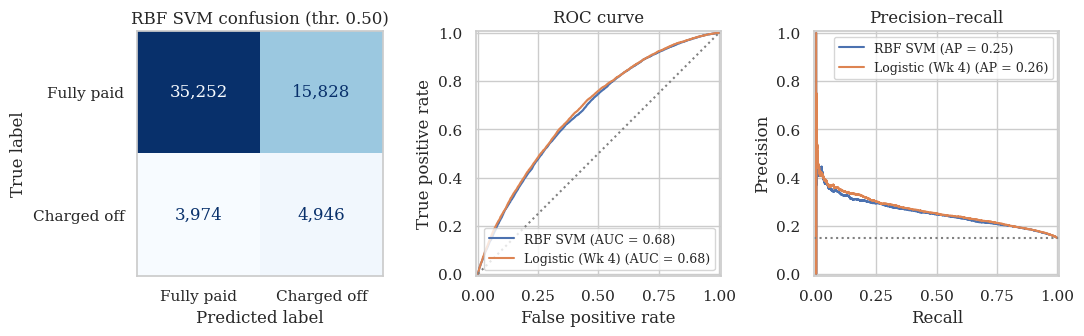

In [9]:
# Figure 5 for the report: selected SVM on the test set
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
ConfusionMatrixDisplay(confusion_matrix(y_te, (s_rbf_te >= THR_RBF).astype(int)),
                       display_labels=["Fully paid", "Charged off"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
axes[0].set_title(f"RBF SVM confusion (thr. {THR_RBF:.2f})")
RocCurveDisplay.from_predictions(y_te, s_rbf_te, ax=axes[1], name="RBF SVM")
RocCurveDisplay.from_predictions(y_te, lr["score"], ax=axes[1], name="Logistic (Wk 4)")
axes[1].plot([0, 1], [0, 1], ls=":", c="grey"); axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_te, s_rbf_te, ax=axes[2], name="RBF SVM")
PrecisionRecallDisplay.from_predictions(y_te, lr["score"], ax=axes[2], name="Logistic (Wk 4)")
axes[2].axhline(y_te.mean(), ls=":", c="grey"); axes[2].set_title("Precision–recall")
axes[0].grid(False)
axes[1].set(xlabel="False positive rate", ylabel="True positive rate")
axes[2].set(xlabel="Recall", ylabel="Precision")
for a in axes[1:]: a.legend(fontsize=9, loc="lower right" if a is axes[1] else "upper right")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_svm_evaluation.png", dpi=200); plt.show()

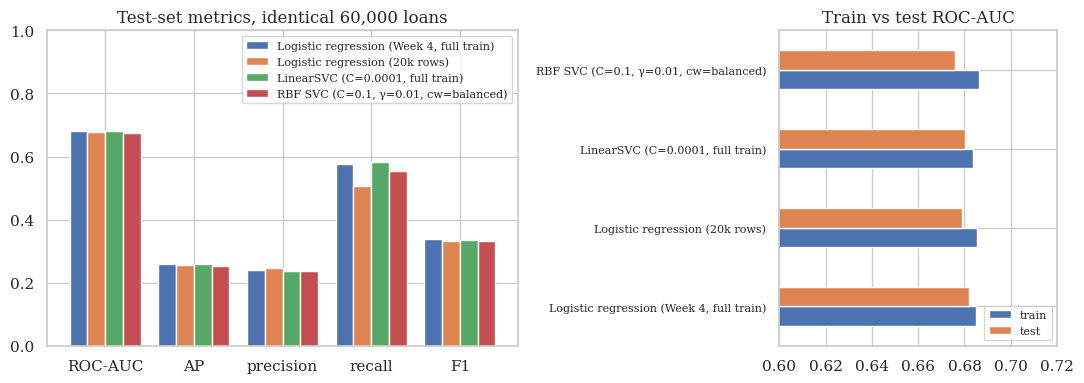

In [10]:
# Figure 6 for the report: logistic vs SVM, with train-test gap
cols = ["ROC_AUC", "PR_AUC(AP)", "precision", "recall", "F1"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2.2, 1.3]})
svm_cmp[cols].T.rename(index={"ROC_AUC": "ROC-AUC", "PR_AUC(AP)": "AP"}).plot.bar(ax=axes[0], rot=0, width=0.8)
axes[0].set(title=f"Test-set metrics, identical {len(y_te):,} loans", ylim=(0, 1)); axes[0].legend(fontsize=8)
svm_cmp[["train_ROC_AUC", "ROC_AUC"]].rename(columns={"ROC_AUC": "test_ROC_AUC"}).plot.barh(ax=axes[1])
axes[1].set(title="Train vs test ROC-AUC", xlim=(0.6, 0.72), ylabel=""); axes[1].legend(["train", "test"], fontsize=8, loc="lower right"); axes[1].set_yticklabels([t.get_text()[:40] for t in axes[1].get_yticklabels()], fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_logistic_vs_svm.png", dpi=200); plt.show()

In [11]:
pd.DataFrame({"id": test["id"].values, "y": y_te.values, "score_rbf": s_rbf_te, "thr_rbf": THR_RBF,
              "score_linsvc": s_lin_te, "thr_linsvc": THR_LIN}).to_parquet(RES_DIR / "week5_svm_test_scores.parquet", index=False)
pd.Series({"linear_fit_s": lin_secs, "rbf_fit_s": rbf_secs, "rbf_predict_s": pred_secs,
           "rbf_support_vectors": int(rbf_svm["svm"].n_support_.sum())}).to_frame("value")

,value
linear_fit_s,0.8710
rbf_fit_s,11.2750
rbf_predict_s,51.2550
rbf_support_vectors,"16,369.0000"


## 6. Conclusions

**Kernel trick.** On the 2-D FICO × DTI demonstration, the linear SVM draws a straight cut and the RBF kernel with γ = 0.5 bends it, with similar training accuracy (0.58). With γ = 50 the boundary becomes small islands around individual loans and training accuracy jumps to 0.69, which is memorized noise.

**Regularization.** For the RBF SVM, CV ROC-AUC peaks at C = 0.1 and γ = 0.01 with balanced weights (0.688), with a train−CV gap of only 0.016. Larger C or γ widens the gap to 0.40 (C = 10, γ = 0.1: train 1.00 vs. CV 0.60), the clearest overfitting in the project. LinearSVC is best at the smallest C tried (10⁻⁴), meaning strong regularization.

**SVM vs. logistic regression.** On the identical 60,000 test loans, the RBF SVM (ROC-AUC 0.676) does not beat logistic regression trained on the same 20,000 rows (0.679) or on the full training set (0.682). The gap is therefore not just a matter of less training data: a nonlinear boundary adds nothing here, consistent with mostly monotone credit relationships.

**Precision/recall.** At each model's chosen threshold, the RBF SVM catches fewer charge-offs (recall 55% vs. 58%) at about the same precision (24%), so it is not a better screen.

**Cost and interpretability.** The RBF SVM keeps 16,369 support vectors (82% of its training rows), took 11 s to fit on 20,000 rows, and 51 s to score the test set, while LinearSVC fits the full 140,000 rows in about 1 s. With no accuracy gain and no coefficient-level explanations, it is the wrong choice for a lender that must explain adverse decisions.
